In [2]:
# Run this cell to fix the pandas circular import/compatibility error on Python 3.13
!pip install --upgrade --force-reinstall pandas numpy
print("\n--- Pandas has been reinstalled. PLEASE RESTART YOUR SESSION (Runtime > Restart session) before running other cells --- ")

  Using cached pandas-3.0.6-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached numpy-2.5.3-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cached pandas-3.0.6-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (10.8 MB)
Using cached numpy-2.5.3-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl (229 kB)
Using cached six-1.17.0-py2.py3-none-any.whl (11 kB)
  Attempting uninstall: six
    Found existing installation: six 1.17.0
    Uninstalling six-1.17.0:
      Successfully uninstalled six-1.17.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.3
    Uninstalling numpy-2.5.3:
      Successfully uninstalled numpy-2.5.3
  Attempting uninstall: python-dateut


--- Pandas has been reinstalled. PLEASE RESTART YOUR SESSION (Runtime > Restart session) before running other cells --- 


In [3]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate 1000 records
n_samples = 1000

# Generate 7 columns of dummy loan data
data = {
    'Loan_ID': [f'LP{i:04d}' for i in range(1, n_samples + 1)],
    'Applicant_Income': np.random.randint(2000, 15000, size=n_samples),
    'Loan_Amount': np.random.randint(10, 500, size=n_samples) * 1000,
    'Credit_Score': np.random.randint(300, 850, size=n_samples),
    'Term_Months': np.random.choice([120, 180, 240, 360], size=n_samples, p=[0.1, 0.1, 0.1, 0.7]),
    'Employment_Years': np.random.randint(0, 40, size=n_samples),
    'Loan_Status': []
}

# Map status clearly to two values: 'Approved' and 'Rejected'
for i in range(n_samples):
    income = data['Applicant_Income'][i]
    amount = data['Loan_Amount'][i]
    score = data['Credit_Score'][i]

    if score >= 650 and (income * 12 > amount * 0.4):
        status = 'Approved'
    else:
        status = 'Rejected'
    data['Loan_Status'].append(status)

# Create DataFrame
df = pd.DataFrame(data)

# Save to csv
df.to_csv('loan_dummy_dataset.csv', index=False)

# Display DataFrame properties and preview
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1000, 7)


,Loan_ID,Applicant_Income,Loan_Amount,Credit_Score,Term_Months,Employment_Years,Loan_Status
0,LP0001,9270,475000,423,360,29,Rejected
1,LP0002,2860,101000,337,360,24,Rejected
2,LP0003,7390,179000,627,360,27,Rejected
3,LP0004,7191,326000,550,360,0,Rejected
4,LP0005,13964,31000,475,360,3,Rejected


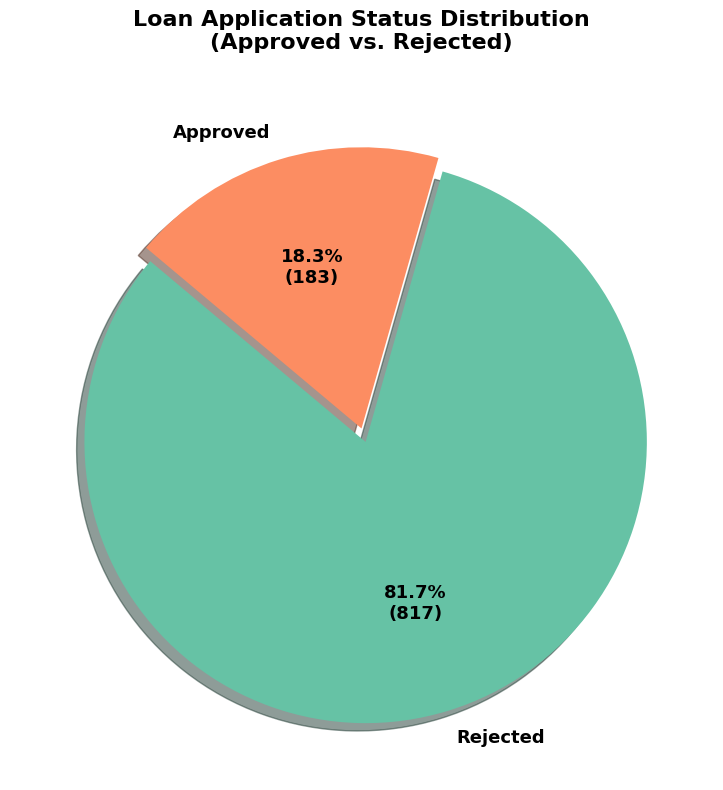

In [11]:
import matplotlib.pyplot as plt

# Count the occurrences of each status
status_counts = df['Loan_Status'].value_counts()

# Custom styling for a clean pie chart
plt.figure(figsize=(8, 8))
colors = ['#66c2a5', '#fc8d62']  # Teal for Approved, Coral for Rejected

# Helper function to display both percentage and raw counts
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct*total/100.0))
        return f'{pct:.1f}%\n({val:d})'
    return my_autopct

# Create the pie chart
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct=make_autopct(status_counts),
    startangle=140,
    colors=colors,
    textprops=dict(color="black", fontsize=13, weight="bold"),
    shadow=True,
    explode=(0.05, 0) # Explode the Approved slice slightly
)

plt.title('Loan Application Status Distribution\n(Approved vs. Rejected)', fontsize=16, weight='bold', pad=20)
plt.tight_layout()
plt.show()

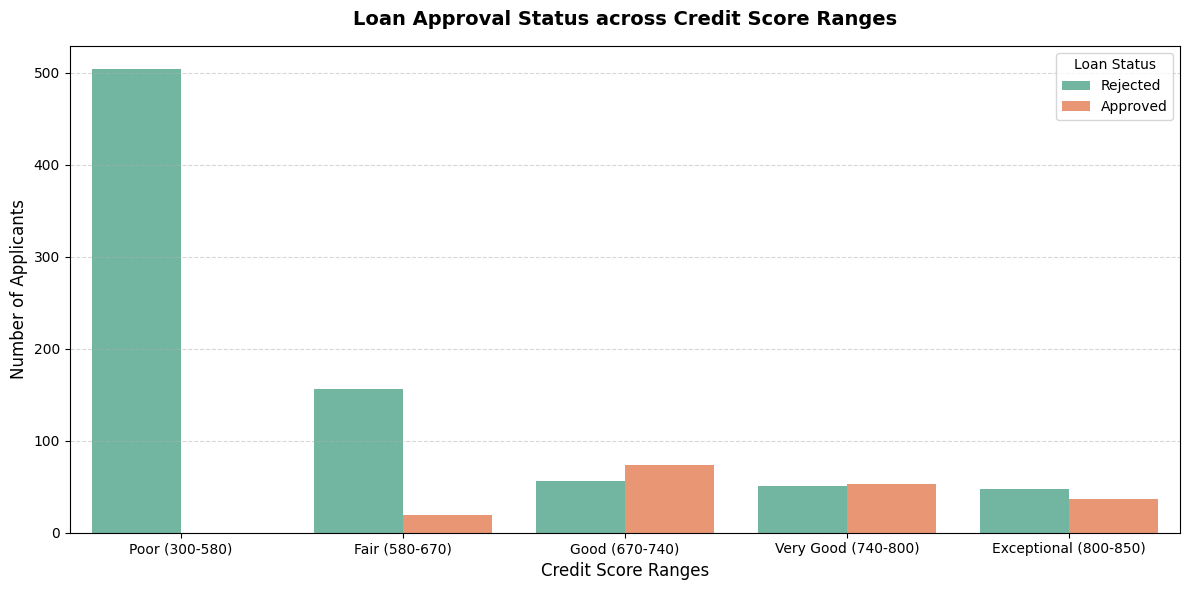

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group Credit Scores into categories for a meaningful bar chart comparison
if 'df' in globals():
    df_plot = df.copy()
    df_plot['Credit_Range'] = pd.cut(
        df_plot['Credit_Score'],
        bins=[300, 580, 670, 740, 800, 850],
        labels=['Poor (300-580)', 'Fair (580-670)', 'Good (670-740)', 'Very Good (740-800)', 'Exceptional (800-850)']
    )

    # Generate grouped bar chart
    plt.figure(figsize=(12, 6))
    sns.countplot(data=df_plot, x='Credit_Range', hue='Loan_Status', palette=['#66c2a5', '#fc8d62'])
    plt.title('Loan Approval Status across Credit Score Ranges', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Credit Score Ranges', fontsize=12)
    plt.ylabel('Number of Applicants', fontsize=12)
    plt.legend(title='Loan Status')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("Error: Dataset 'df' is not defined. Please run cell a62aa264 first.")

### Visualizing Dataset Distributions via Bar Charts

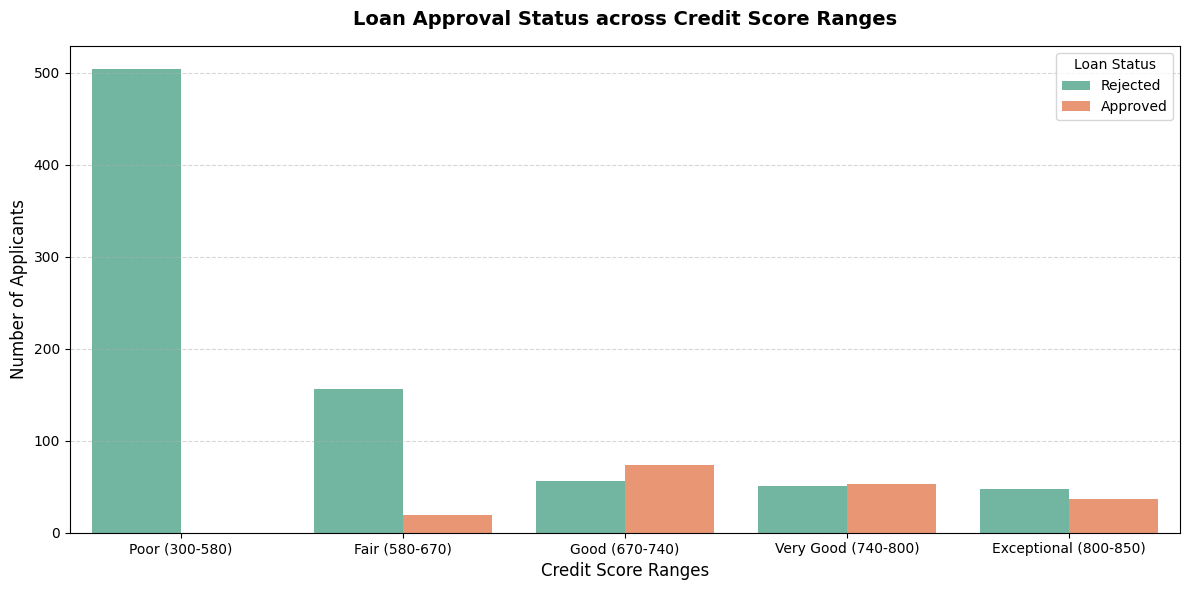

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group Credit Scores into categories for a meaningful bar chart comparison
if 'df' in globals():
    df_plot = df.copy()
    df_plot['Credit_Range'] = pd.cut(
        df_plot['Credit_Score'],
        bins=[300, 580, 670, 740, 800, 850],
        labels=['Poor (300-580)', 'Fair (580-670)', 'Good (670-740)', 'Very Good (740-800)', 'Exceptional (800-850)']
    )

    # Generate grouped bar chart
    plt.figure(figsize=(12, 6))
    sns.countplot(data=df_plot, x='Credit_Range', hue='Loan_Status', palette=['#66c2a5', '#fc8d62'])
    plt.title('Loan Approval Status across Credit Score Ranges', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Credit Score Ranges', fontsize=12)
    plt.ylabel('Number of Applicants', fontsize=12)
    plt.legend(title='Loan Status')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("Error: Dataset 'df' is not defined. Please verify that the initialization cell executed correctly.")

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Prepare Features (X) and Target (y)
X = df.drop(columns=['Loan_ID', 'Loan_Status'])
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Make predictions
y_pred = model.predict(X_test_scaled)

# 6. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.9150

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       163
           1       0.75      0.81      0.78        37

    accuracy                           0.92       200
   macro avg       0.85      0.87      0.86       200
weighted avg       0.92      0.92      0.92       200



### Custom Data Input & Model Testing Interface
Use the form below to enter custom financial and background credentials to test how the trained Logistic Regression model will classify the loan status (Approved vs. Rejected).

In [10]:
#@title Loan Status Prediction Form { run: "auto" }

# Ensure the model and scaler are available.
# (If you restarted the runtime, please make sure cell a62aa264 and cell 08990a73 have run successfully.)

try:
    # 1. Grab inputs from the form fields
    Applicant_Income = 500000 #@param {type:"integer"}
    Loan_Amount = 150000 #@param {type:"integer"}
    Credit_Score = 580 #@param {type:"slider", min:300, max:850, step:10}
    Term_Months = 120 #@param [120, 180, 240, 360] {type:"raw"}
    Employment_Years = 8 #@param {type:"slider", min:0, max:40, step:1}

    # 2. Build the input feature array matching the columns:
    # ['Applicant_Income', 'Loan_Amount', 'Credit_Score', 'Term_Months', 'Employment_Years']
    input_features = np.array([[Applicant_Income, Loan_Amount, Credit_Score, Term_Months, Employment_Years]])

    # 3. Scale input data using the pre-fitted scaler
    input_scaled = scaler.transform(input_features)

    # 4. Predict probability and class
    prediction = model.predict(input_scaled)[0]
    probability = model.predict_proba(input_scaled)[0]

    # 5. Display stylized output
    status_label = "APPROVED" if prediction == 1 else "REJECTED"
    confidence = probability[1] if prediction == 1 else probability[0]
    color = "#2ca02c" if prediction == 1 else "#d62728"

    from IPython.display import HTML, display
    display(HTML(f"""
    <div style="padding: 20px; border-radius: 8px; background-color: #f7f9fa; border-left: 8px solid {color}; max-width: 500px;">
        <h3 style="margin-top: 0; color: #333;">Prediction Result</h3>
        <p style="font-size: 18px; margin: 10px 0;">
            Status: <strong style="color: {color};">{status_label}</strong>
        </p>
        <p style="font-size: 14px; color: #555;">
            Confidence Level: <strong>{confidence * 100:.2f}%</strong>
        </p>
    </div>
    """))
except NameError as e:
    print("Error: Model or Scaler not found. Please ensure that you run the training cell (08990a73) first to build and train the model before testing inputs!")


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


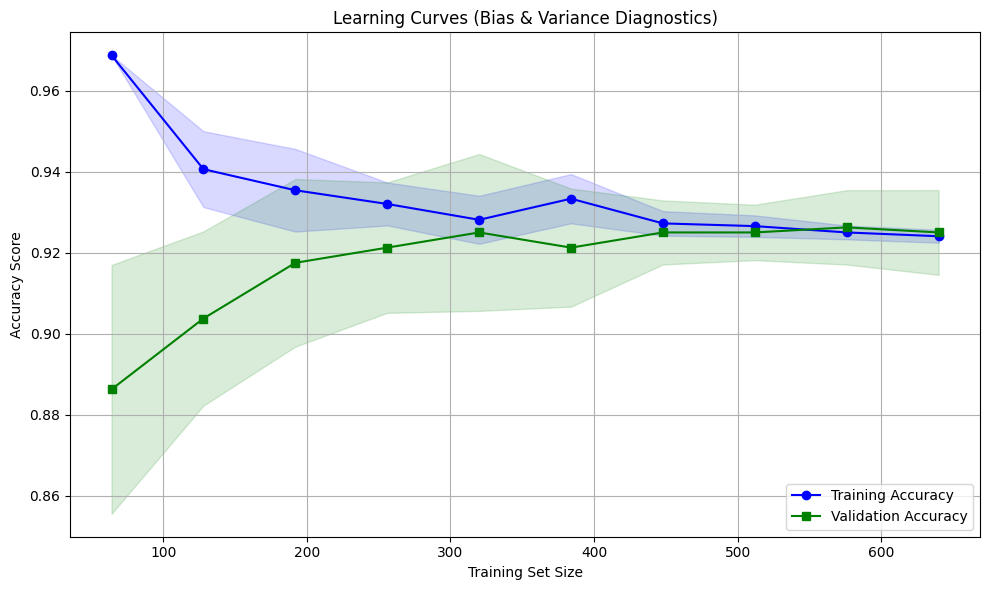

In [8]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Calculate learning curves
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10),
    random_state=42
)

# Calculate mean and standard deviation for training and test sets
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot the learning curves
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Accuracy')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, test_mean, 's-', color='green', label='Validation Accuracy')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')

plt.title('Learning Curves (Bias & Variance Diagnostics)')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy Score')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()


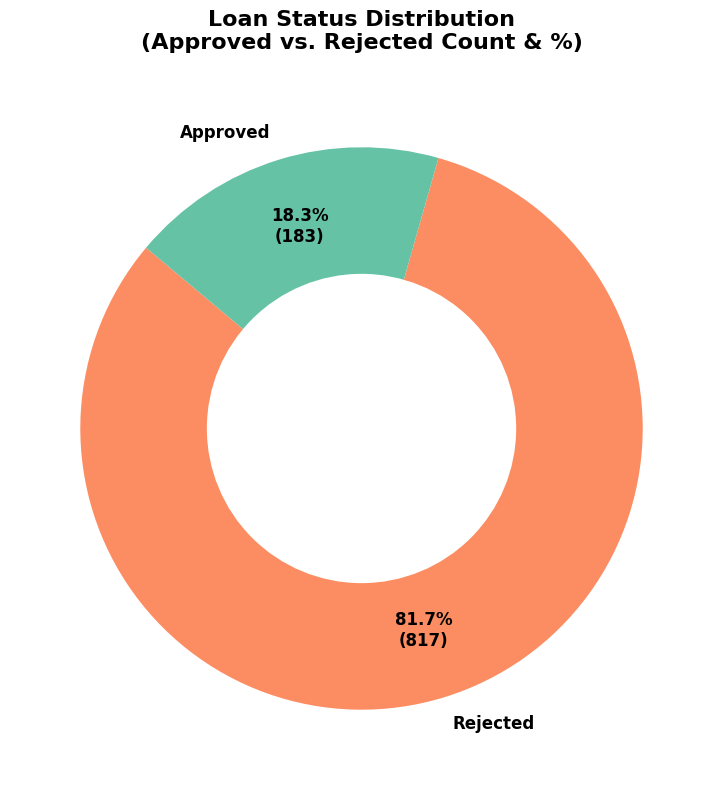

In [9]:
import matplotlib.pyplot as plt

# Count the occurrences of each status
status_counts = df['Loan_Status'].value_counts()

# Custom styling for a modern donut chart
plt.figure(figsize=(8, 8))
colors = ['#fc8d62', '#66c2a5'] # Coral for Rejected, Teal for Approved

# Function to display both percentage and raw count
def pct_and_count(pct, allvals):
    absolute = int(round(pct/100.*sum(allvals)))
    return f"{pct:.1f}%\n({absolute:,d})"

# Create pie chart
wedges, texts, autotexts = plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct=lambda pct: pct_and_count(pct, status_counts),
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    textprops=dict(color="black", fontsize=12, weight="bold")
)

# Add a center circle to transform it into a donut chart
centre_circle = plt.Circle((0,0), 0.55, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Loan Status Distribution\n(Approved vs. Rejected Count & %)', fontsize=16, weight='bold', pad=20)
plt.tight_layout()
plt.show()